In [ ]:
"""
Code for Appendix B: Sensitivity of SCEN - HIST comparisons to residual mean-state warming in 2041-2050
-------------------------------------------------------------------------------------------

This notebook contains the plotting code that creates Figures B1-B2 and Table B1 of 'Appendix B'. 
The data used can be found in data/processed in the root of this repository, which have been created 
by enso_preprocessing.py (Niño 3.4 Hovmöllers, ONI statistics, ENSO event timestamps and flavour proportions) 
and appendix_A.ipynb (composite differences with significance and the extreme-temperature bootstrap files). 
The bootstrap significance tests behind Figures B1 and B2e-f are run in this notebook.

Author: Sreevathsa G. (sg13n23@soton.ac.uk; ORCID ID: 0000-0003-4084-9677)
Last updated: 25 November 2026
"""

In [ ]:
# Standard library
import glob
from pathlib import Path
import pickle
import sys

# Third-party
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, to_rgba
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import xarray as xr

# Local modules
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils import add_colorbar, flatten, format_axis, merge_pngs_vertical

# Cartopy features
land_50m = cfeature.NaturalEarthFeature("physical", "land", "50m", edgecolor="face", facecolor="grey")
coast_50m = cfeature.NaturalEarthFeature("physical", "coastline", "50m", edgecolor="black", facecolor="none")

In [3]:
# Directories (relative to this notebook)
DATA_DIR = '../data/processed/'
Z20_DIR  = '../data/z20_depths/'
FIG_DIR  = '../figures/'

# Dataset and experiment names (HIST: 1979-2014, SCEN: 2015-2050)
HIGHRESMIP_MODELS = ["HadGEM3-GC31-HH", "EC-Earth3P-HR", "CNRM-CM6-1-HR",
                     "CMCC-CM2-VHR4", "MPI-ESM1-2-HR", "MPI-ESM1-2-XR",]

HIGHRESMIP_EXPS_HIST = [f"{model}_HIST" for model in HIGHRESMIP_MODELS]
HIGHRESMIP_EXPS_SCEN = [f"{model}_SCEN" for model in HIGHRESMIP_MODELS]

# Experiment groups of Table B1: HIST, SCEN_F (full SCEN) and SCEN_T (truncated SCEN), with the period label used in
# their file names and their datasets
PERIOD_LABELS = {'HIST': 'HIST_EVAL_1979-2014', 'SCEN_F': 'FUTR_EVAL_2015-2050', 'SCEN_T': 'TRNC_SCEN_2015-2040'}
EXP_DATASETS = {'HIST': HIGHRESMIP_EXPS_HIST, 'SCEN_F': HIGHRESMIP_EXPS_SCEN, 'SCEN_T': HIGHRESMIP_EXPS_SCEN}

# Block-bootstrap settings shared by FIGURE B1 (block-mean significance) and FIGURE B2e-f (mean / variance profiles)
BLOCK_SIZE = 24 # Block length in months (2 years)
N_SIM = 2000 # Number of bootstrap iterations

### Figure B1: Five-year block-mean Niño 3.4 temperature anomalies at surface and subsurface, as individual and multi-model mean (MMM) of HighResMIP models

In [ ]:
# Niño 3.4 depth-time (Hovmöller) anomalies of the top 300 m, FUTR_EVAL period (2015-2050): dims (dataset, time, depth) for the 6 SCEN runs
n34_hov = xr.open_dataarray(f"{DATA_DIR}N34_HOV_ZVT_TOP300M_FUTR_EVAL_2015-2050.nc")

# 5-year blocks (+ a 10-year block representing 2041-2050) for computing block means
blocks = ['2015-2020', '2021-2025', '2026-2030', '2031-2035', '2036-2040', '2041-2045', '2046-2050', '2041-2050']

# Helper function to compute the mean of a DataArray over each time block
def block_mean(da, blocks):
    """
    Compute the mean of a DataArray over each time block, plus the mean across datasets.

    Parameters
    ----------
    da (xr.DataArray)    : Anomalies with dims including 'time' and 'dataset'.
    blocks (list of str) : Time blocks as 'YYYY-YYYY' strings (first and last year, both inclusive).

    Returns
    -------
    xr.Dataset : Variable 'N34_SSTA' with a 'block_idx' dimension (and a 'block' coordinate holding the
                 block names). The mean across datasets is appended along 'dataset' as 'GROUP-MEAN'.
    """
    da_block_mean = []
    for i, block in enumerate(blocks):
        blk_mean = da.sel(time = slice(block.split('-')[0], block.split('-')[1])).mean(dim = 'time')
        blk_mean = blk_mean.expand_dims(dim = {"block_idx":[i]})
        da_block_mean += [blk_mean.rename('N34_SSTA')]
    da_block_mean = xr.concat(da_block_mean, dim = 'block_idx').to_dataset().assign_coords(block = ("block_idx", blocks))
    da_block_mean = xr.concat([da_block_mean, da_block_mean.mean(dim = 'dataset').expand_dims(dataset = ['GROUP-MEAN'])], dim = 'dataset')
    return da_block_mean

# Helper function to compute the linear trend of a time series
def linear_trend(da, dim="time"):
    """
    Linear trend of a time series along 'dim': returns the fitted values and the slope (units of da per year).
    """
    # Time in years since the first step, used as the regression variable
    years = (da[dim] - da[dim][0]) / np.timedelta64(1, "D") / 365.25
    da_t = da.assign_coords(t=(dim, years.values))
    coeffs = da_t.polyfit(dim="t", deg=1)
    slope = coeffs.polyfit_coefficients.sel(degree=1).item()
    fit = xr.polyval(da_t["t"], coeffs.polyfit_coefficients).assign_coords({dim: da[dim]})

    return fit, slope

In [5]:
# Linear trends (°C/yr) of the multi-model-mean Niño 3.4 SSTA at depth = 0 m, for 2015-2040 and 2041-2050
_, slope_pre2040 = linear_trend(n34_hov.mean(dim = 'dataset').sel(time = slice('2015', '2040'), depth = 0))
_, slope_post2040 = linear_trend(n34_hov.mean(dim = 'dataset').sel(time = slice('2041', '2050'), depth = 0))

In [6]:
# =============================================================================
# SIGNIFICANCE OF THE 5-YEAR BLOCK MEANS (TWO-LEVEL BLOCK BOOTSTRAP)
# =============================================================================
# Each dataset's 2015-2040 reference period is cut into BLOCK_SIZE-month blocks, which are resampled with replacement
# into a full-length (2015-2050) series without residual warming; the datasets are resampled too (two levels). The block
# means of the multi-model mean are computed for each of the N_SIM draws, and their 2.5-97.5% range is the 95% interval

rng = np.random.default_rng(seed=32)

# Actual block means (all datasets + GROUP-MEAN)
actual_block_mean = block_mean(n34_hov, blocks)

# Reference period: the only period where 5-year blocks have centred 30-year baselines
# (2015-2040) and are not 'contaminated' by residual warming post-2040
REF_PERIOD = ('2015', '2040')

boot_block_mean = [] # Block means (GROUP-MEAN only) of each bootstrap iteration
for i in tqdm(range(N_SIM)):
    # Level 1: resample the datasets with replacement
    resampled_n34_hov = n34_hov.isel(dataset = rng.integers(0, n34_hov.dataset.shape[0], size=n34_hov.dataset.shape[0]))
    # Level 2: cut the 2015-2040 reference period of each dataset into blocks of BLOCK_SIZE months (312 months -> 13 blocks)
    ref_blocks = resampled_n34_hov.sel(time = slice(*REF_PERIOD)).values
    ref_blocks = ref_blocks.reshape(ref_blocks.shape[0], ref_blocks.shape[1] // BLOCK_SIZE, BLOCK_SIZE, ref_blocks.shape[-1])
    # Resample these blocks with replacement, separately for each dataset, into full-length 2015-2050 series (432 months -> 18 blocks)
    n_blocks = resampled_n34_hov.sizes['time'] // BLOCK_SIZE
    resampled = np.stack([ds_blocks[rng.integers(0, ds_blocks.shape[0], size=n_blocks)] for ds_blocks in ref_blocks]).reshape(resampled_n34_hov.shape)
    resampled_n34_hov = resampled_n34_hov.copy(data = resampled).rename('anomaly_resampled').expand_dims({'boot':[i]})
    boot_block_mean += [block_mean(resampled_n34_hov, blocks).sel(dataset = 'GROUP-MEAN')]
boot_block_mean = xr.concat(boot_block_mean, dim = 'boot')
# 95% interval of the multi-model-mean block means
ci = boot_block_mean.quantile(q = [0.025, 0.975], dim = 'boot')
# An actual block mean is significant if it lies outside this interval
significance_mask = (actual_block_mean["N34_SSTA"] < ci["N34_SSTA"].sel(quantile=0.025, drop=True)) | (actual_block_mean["N34_SSTA"] > ci["N34_SSTA"].sel(quantile=0.975, drop=True))

  0%|          | 0/2000 [00:00<?, ?it/s]

Flag


/tmp/ipykernel_227464/4135390164.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(tick_labels)


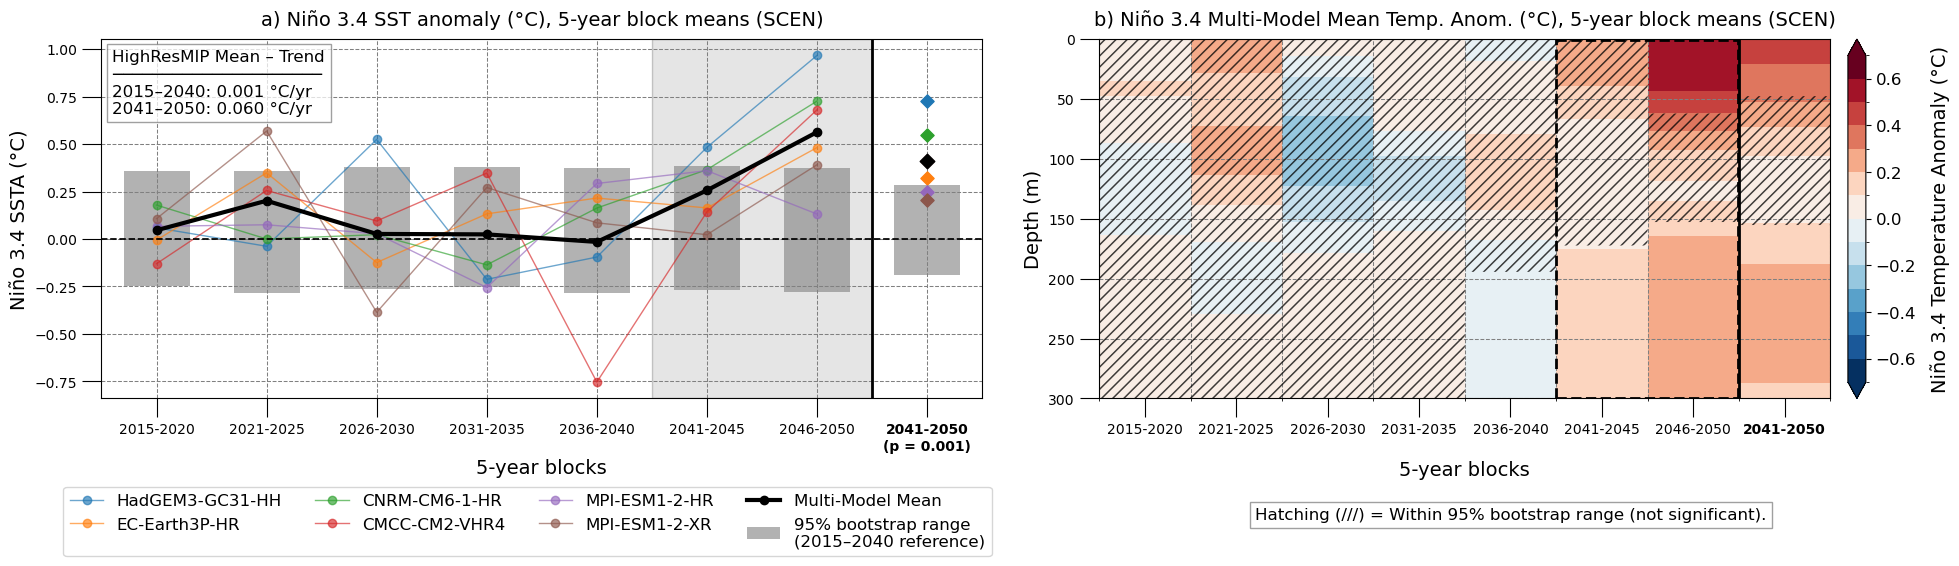

In [7]:
# =============================================================================
# FIGURE B1: 5-YEAR BLOCK MEANS OF NIÑO 3.4 TEMPERATURE ANOMALIES (SCEN)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

# x positions (block_idx - 0.5 / + 0.5): the 5-year blocks of 2041-2050 span x_2041 to x_2050, the 10-year block follows
x_2041, x_2050 = blocks.index('2041-2045') - 0.5, blocks.index('2041-2050') - 0.5
grid_kw = dict(color="gray", ls="--", lw=0.75)

# Panel a: surface (0 m) block means of each model (thin lines) and of the multi-model mean (MMM, thick line). The 10-year
# block (2041-2050, last block_idx) is drawn as a diamond to set it apart from the seven 5-year blocks
mean_data = actual_block_mean["N34_SSTA"].sel(dataset="GROUP-MEAN", depth=0)
series = [(actual_block_mean["N34_SSTA"].sel(depth=0, dataset=f"{model}_SCEN"), f"C{i}", model, dict(lw=1, alpha=0.65), 45)
          for i, model in enumerate(HIGHRESMIP_MODELS)]
series += [(mean_data, "k", "Multi-Model Mean", dict(lw=3), 55)]
for data, color, label, line_kw, size in series:
    data.isel(block_idx=slice(0, -1)).plot(ax=axes[0], x="block", marker="o", markersize=6, color=color, label=label, **line_kw)
    last = data.isel(block_idx=-1)
    axes[0].scatter(last["block"].item(), last.item(), color=color, s=size, zorder=5, marker="D")

# 95% bootstrap range of the MMM block means, as grey bars
lower = ci["N34_SSTA"].sel(quantile=0.025, depth=0).values
upper = ci["N34_SSTA"].sel(quantile=0.975, depth=0).values
axes[0].bar(actual_block_mean.block, upper - lower, bottom=lower, width=0.6,color="grey", alpha=0.6, label="95% bootstrap range\n(2015–2040 reference)")

# Axes styling
axes[0].set_xlabel("5-year blocks", fontsize=14)
axes[0].set_ylabel("Niño 3.4 SSTA (°C)", fontsize=14)
axes[0].set_title("a) Niño 3.4 SST anomaly (°C), 5-year block means (SCEN)", fontsize=14, pad = 10)
axes[0].axhline(0, color="k", ls="--", lw=1.25)
axes[0].axvspan(x_2041, x_2050, facecolor="grey", alpha=0.2, edgecolor = 'black') # Blocks 2041-2045 and 2046-2050 (block_idx 5-6)
axes[0].grid(True, **grid_kw)

# MMM trends before and after 2040
separator = "─" * 21
axes[0].text(-0.4, 0.66, f"HighResMIP Mean – Trend\n{separator}\n" f"2015–2040: {slope_pre2040:.3f} °C/yr\n" f"2041–2050: {slope_post2040:.3f} °C/yr",
             fontsize=12, bbox=dict(facecolor="white", alpha=0.75, edgecolor="gray"))

# Panel b: MMM block means over depth (0-300 m); hatching marks block means inside the 95% bootstrap range (not significant)
cmap = plt.get_cmap("RdBu_r")
norm = BoundaryNorm(np.arange(-0.7, 0.71, 0.1), ncolors=cmap.N, clip=True)

p = actual_block_mean["N34_SSTA"].sel(dataset = 'GROUP-MEAN').plot(ax=axes[1], x="block_idx", y="depth", cmap=cmap, norm=norm, extend="both", yincrease=False, edgecolor='face',
                                                                 cbar_kwargs={"pad": 0.02})
p.colorbar.ax.tick_params(labelsize=12)
p.colorbar.set_label("Niño 3.4 Temperature Anomaly (°C)", size=14, labelpad = 10)

mask = significance_mask.sel(dataset = 'GROUP-MEAN').transpose("depth", "block_idx").values.astype(bool)
axes[1].pcolor(actual_block_mean.block_idx.values, actual_block_mean.depth.values, np.ma.masked_where(mask, ~mask), shading="nearest", hatch="///", alpha=0, zorder=3)

# Axes styling; dashed box around the 2041-2050 blocks (block_idx 5-6) over the full 0-300 m depth range
x_box_end = 6.49 # Just inside x_2050, so that the box does not overlap the solid line at x_2050
for x in (x_2041, x_box_end):
    axes[1].axvline(x, color="k", ls="--", lw=2)
for y in (0.75, 299.25):
    axes[1].hlines(y, x_2041, x_box_end, color="k", ls="--", lw=2)

axes[1].set(xlim=(-0.5, len(blocks) - 0.5), ylim=(300, 0), xticks=np.arange(len(blocks)), xticklabels=blocks, yticks=np.arange(0, 301, 50))
axes[1].set_xlabel("5-year blocks", fontsize=14, labelpad = 17)
axes[1].set_ylabel("Depth (m)", fontsize=14)
axes[1].set_title("b) Niño 3.4 Multi-Model Mean Temp. Anom. (°C), 5-year block means (SCEN)", fontsize=14, pad = 10)
axes[1].grid(True, axis="y", **grid_kw)
axes[1].set_xticks(np.arange(-0.5, len(blocks)), minor=True)
axes[1].grid(True, which="minor", axis="x", **grid_kw)

# One-sided p-value of the 2041-2050 MMM surface block mean: share of bootstrap block means that are >= the actual one
actual_MMM_2041_50 = mean_data.isel(block_idx = -1).item()
p_val_2041_50 = (boot_block_mean["N34_SSTA"].isel(block_idx = -1, depth = 0) >= actual_MMM_2041_50).mean().item()
for ax in axes:
    ax.tick_params(axis="both", size=14)
    # Last x tick label (2041-2050) in bold, with the p-value added in panel a; solid line separates the 10-year block
    tick_labels = ax.get_xticklabels()
    last_label = tick_labels[-1]
    if ax == axes[0]:
        current_text = last_label.get_text()
        last_label.set_text(f"{current_text}\n(p = {p_val_2041_50:.3f})")
        ax.set_xlim([-0.5, len(blocks) - 0.5])
    last_label.set_fontweight("bold")
    ax.set_xticklabels(tick_labels)
    ax.axvline(x_2050, color="k", ls="-", lw=2)

# Hatching key and a shared legend (taken from panel a) below the figure
fig.text(0.63, -0.05,'Hatching (///) = Within 95% bootstrap range (not significant).', fontsize=12, bbox=dict(facecolor="white", alpha=0.75, edgecolor="gray"))
fig.tight_layout(w_pad=3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol = 4, fontsize = 12, loc = 'lower left', frameon = True, bbox_to_anchor = (0.03, -0.14))

fig.savefig(f"{FIG_DIR}figure_B1.png", dpi = 300, bbox_inches = 'tight')

### Figure B2: Differences in ENSO SST anomalies, Niño 3.4 event-centred composites, anomaly statistics, and extreme anomaly intensity between the full (F) and truncated (T) scenarios relative to HIST, showing statistical significance.

In [8]:
# =============================================================================
# READING IN THE SCEN - HIST COMPOSITE DIFFERENCES WITH SIGNIFICANCE (FIGURE B2a-d)
# =============================================================================
# Results of appendix_A.ipynb: 'comp' holds group means and group differences (here SCEN_T-HIST and SCEN_F-HIST), 'D' the
# group-mean difference, 'sig' a boolean mask that is True where the difference is significant. ds_ssta is on a lat-lon
# grid (30S-30N, 120-290E); ds_n34_hov on event-centred time (-14 to +8 months) and depth
ds_ssta = xr.open_dataset(f'{DATA_DIR}ENSO_SSTA_COMP_DIFF_RESULTS_WITH_SIG.nc')
ds_n34_hov = xr.open_dataset(f'{DATA_DIR}ENSO_N34_HOV_COMP_DIFF_RESULTS_WITH_SIG.nc')

In [10]:
# Helper function to compute, for one ENSO phase, the % of significant points and the mean temperature difference
def significance_fraction_and_mean_temp_diff(ds, phase):
    """
    Compute the % of significant points and the mean temperature difference for one ENSO phase.

    Land (NaN) points are excluded from the significance fraction. SSTA maps are cropped to the tropical
    Pacific (30S-30N, 140-290E); Hovmöller data use the whole event window (-14 to +8 months).

    Parameters
    ----------
    ds (xr.Dataset) : One comparison (e.g. SCEN_T-HIST) with variables 'D' (difference) and 'sig' (boolean
                      significance mask), either on a (lat, lon) grid or on (time, depth).
    phase (str)     : 'EL-NINO' or 'LA-NINA'.

    Returns
    -------
    sig_frac (float)       : Percentage of significant ocean points.
    mean_temp_diff (float) : Mean temperature difference in °C, weighted by cos(latitude) for maps and a plain mean over
                             time and depth for Hovmöllers.
    """
    if 'lat' in list(ds.dims):
        # SSTA maps: tropical Pacific, 30S-30N and 140-290E
        ds_sel = ds.sel(phase = phase, lat = slice(-30,30), lon = slice(140,290))
    else:
        # Hovmöller: the whole event window, -14 to +8 months
        ds_sel = ds.sel(phase = phase, time = slice(-14,8))
    # Land mask: True where the difference is NaN
    mask = ds['D'].sel(phase = phase).isnull()
    # Significance (True / False) of the ocean points only, as a 1D array
    sig_masked = ds_sel['sig'].where(mask == False)
    sig_masked = sig_masked.values.reshape(-1)
    sig_masked = sig_masked[~np.isnan(sig_masked)]
    sig_frac = np.sum(sig_masked)/len(sig_masked)*100

    # Mean difference (°C): weighted by cos(latitude) for the maps, mean over time and depth for the Hovmöller
    if 'lat' in list(ds.dims):
        mean_temp_diff = ds_sel['D'].weighted(np.cos(np.deg2rad(ds_sel.lat))).mean(dim = ['lat', 'lon'], skipna = True).item()
    else:
        mean_temp_diff = ds_sel['D'].mean(dim = ['time', 'depth'], skipna = True).item()
    return sig_frac, mean_temp_diff

/dssgfs01/working/sg13n23/ENSO-HighResMIP-TempAnoms/appendices/utils.py:828: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axhspan(100, 150, color='gray', edgecolor='k', alpha=0.25, linewidth=2)
/tmp/ipykernel_227464/1378400455.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


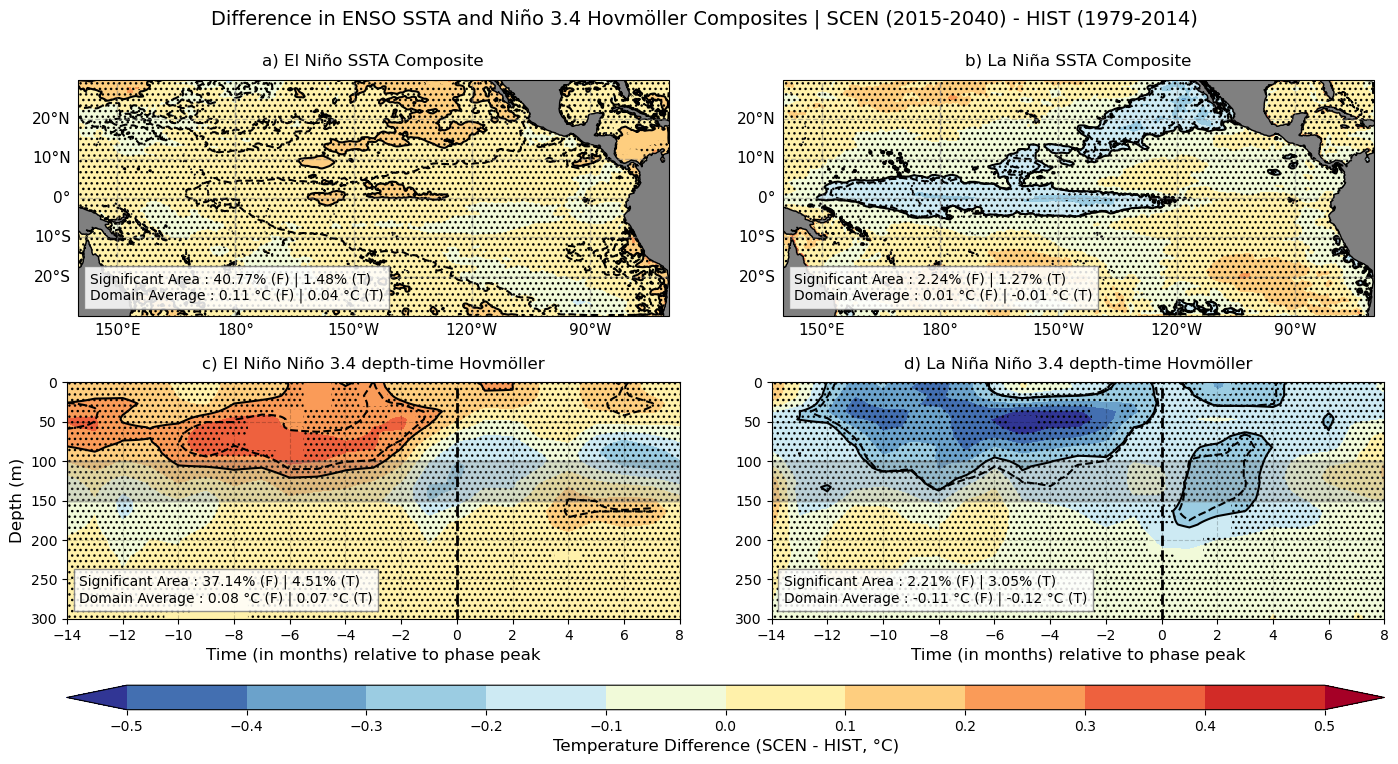

In [11]:
# =============================================================================
# FIGURE B2 (PART 1): SCEN - HIST COMPOSITES OF ENSO SSTA AND NIÑO 3.4 HOVMÖLLERS (PANELS a-d)
# =============================================================================
PHASES = ['EL-NINO', 'LA-NINA']

fig = plt.figure(figsize=(17, 7))
gs = fig.add_gridspec(2, 2, hspace=0.28, wspace=0.15)

# Row 0: maps (a, b); row 1: depth-time Hovmöllers (c, d). Columns: El Niño, La Niña
axes = np.empty((2, 2), dtype=object)
axes[0, 0] = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree(central_longitude=180))
axes[0, 1] = fig.add_subplot(gs[0, 1], projection=ccrs.PlateCarree(central_longitude=180))
axes[1, 0] = fig.add_subplot(gs[1, 0])
axes[1, 1] = fig.add_subplot(gs[1, 1])

levels = np.arange(-0.5, 0.51, 0.1)
cmap = "RdYlBu_r"
# Hatching colour for the points where the difference is not significant
color_shade = to_rgba('black')

# Per row: dataset, size (°C) of the difference contour (positive for El Niño, negative for La Niña) and extra plot arguments
PANEL_ROWS = [(ds_ssta, 0.1, dict(transform=ccrs.PlateCarree())),
              (ds_n34_hov, 0.2, dict(x="time", y="depth"))]

# Filled contours of the SCEN_T-HIST composites, with the difference contour of SCEN_T-HIST (solid) and SCEN_F-HIST (dashed)
mappables = {}
for row, (ds, contour_level, plot_kw) in enumerate(PANEL_ROWS):
    for i, (phase, sign) in enumerate(zip(PHASES, [1, -1])):
        mappables[row, i] = ds.sel(comp = 'SCEN_T-HIST', phase=phase)["D"].plot.contourf(ax=axes[row, i], cmap=cmap, levels=levels,
                                                                                         add_colorbar=False, extend = 'both', **plot_kw)
        for comp, linestyle in [('SCEN_T-HIST', 'solid'), ('SCEN_F-HIST', 'dashed')]:
            ds.sel(comp = comp, phase = phase)['D'].plot.contour(levels = [sign * contour_level], colors='black', add_colorbar = False,
                                                                 ax = axes[row, i], linestyles=linestyle, **plot_kw)

axes[0, 0].set_title("a) El Niño SSTA Composite", fontsize=12, pad = 10)
axes[0, 1].set_title("b) La Niña SSTA Composite", fontsize=12, pad = 10)
axes[1, 0].set_title("c) El Niño Niño 3.4 depth-time Hovmöller", fontsize=12, pad = 10)
axes[1, 1].set_title("d) La Niña Niño 3.4 depth-time Hovmöller", fontsize=12, pad = 10)

# Hatching where the SCEN_T-HIST differences are not significant
for ax, phase in zip(axes[0], PHASES):
    hatch = ax.contourf(ds_ssta.lon, ds_ssta.lat, ds_ssta.sig.sel(comp = 'SCEN_T-HIST', phase=phase).astype(float),
                        levels=[-0.5, 0.5], hatches=["..."], colors="none", transform=ccrs.PlateCarree())
    hatch._hatch_color = color_shade

    format_axis(ax=ax, kind="map", land_ft=land_50m, coast_ft=coast_50m)

for ax, phase, i in zip(axes[1], PHASES, range(2)):
    ax.invert_yaxis()
    hatch = ax.contourf(ds_n34_hov.time, ds_n34_hov.depth, ds_n34_hov.sel(comp = 'SCEN_T-HIST', phase=phase)["sig"].transpose(),
                        levels=[-0.5, 0.5], hatches=["..."], colors="none")
    hatch._hatch_color = color_shade
    format_axis(ax, kind="event_comp", i=i, last_row=True)

# Text box on each panel: % of significant points and mean difference, for SCEN_F-HIST (F) and SCEN_T-HIST (T)
for row, (ds, *_) in enumerate(PANEL_ROWS):
    for i, phase in enumerate(PHASES):
        sig_frac_T, mean_temp_diff_T = significance_fraction_and_mean_temp_diff(ds.sel(comp = 'SCEN_T-HIST'), phase)
        sig_frac_F, mean_temp_diff_F = significance_fraction_and_mean_temp_diff(ds.sel(comp = 'SCEN_F-HIST'), phase)
        axes[row,i].text(0.02, 0.07, f'Significant Area : {sig_frac_F:.2f}% (F) | {sig_frac_T:.2f}% (T)\nDomain Average : {mean_temp_diff_F:.2f} °C (F) | {mean_temp_diff_T:.2f} °C (T)',
                         fontsize=10, bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray"), transform=axes[row,i].transAxes)

fig.suptitle('Difference in ENSO SSTA and Niño 3.4 Hovmöller Composites | SCEN (2015-2040) - HIST (1979-2014)', fontsize=14)
fig.tight_layout()
# Shared colorbar below all panels
add_colorbar(fig, axes = axes.ravel().tolist(), mappable = mappables[0, 0],
             label = 'Temperature Difference (SCEN - HIST, °C)', ticks=levels, side = 'bottom',
             height=0.035, pad = 0.13, labelsize = 12, ticksize = 10)
fig.savefig(f"{FIG_DIR}figure_B2_pt1.png", dpi = 300, bbox_inches = 'tight')

In [12]:
# =============================================================================
# BOOTSTRAP OF NIÑO 3.4 TEMPERATURE ANOMALY STATISTICS, SCEN - HIST (FIGURE B2e-f)
# =============================================================================
# Two-level block bootstrap (datasets, then BLOCK_SIZE-month blocks of time) of the Niño 3.4 Hovmöllers of the top 300 m,
# to test the SCEN_F - HIST and SCEN_T - HIST differences in the mean absolute anomaly and the anomaly variance at each depth

# Niño 3.4 depth-time anomalies of each experiment: HIST (1979-2014), SCEN_F (full SCEN, 2015-2050) and
# SCEN_T (truncated SCEN, 2015-2040; files labelled TRNC_SCEN)
N34_HOV_ZVT = {'HIST': xr.open_dataset(f'{DATA_DIR}N34_HOV_ZVT_TOP300M_HIST_EVAL_1979-2014.nc').sel(dataset=HIGHRESMIP_EXPS_HIST),
               'SCEN_F': xr.open_dataset(f'{DATA_DIR}N34_HOV_ZVT_TOP300M_FUTR_EVAL_2015-2050.nc').sel(dataset=HIGHRESMIP_EXPS_SCEN),
               'SCEN_T': xr.open_dataset(f'{DATA_DIR}N34_HOV_ZVT_TOP300M_TRNC_SCEN_2015-2040.nc').sel(dataset=HIGHRESMIP_EXPS_SCEN)
               }

# Helper function to compute the mean absolute anomaly and the anomaly variance over time, averaged across datasets
def calculate_stats(da, suffix=''):
    """
    Mean absolute anomaly and anomaly variance over time, averaged across datasets.
    """
    return xr.merge([abs(da).mean('time').rename(f'mean{suffix}'), da.var('time').rename(f'var{suffix}')]).mean('dataset')

# Actual statistics of each experiment
ACTUAL_STATS = {label: calculate_stats(ds.anomaly) for label, ds in N34_HOV_ZVT.items()}

rng = np.random.default_rng(seed=42)
boot_stats = {label: [] for label in N34_HOV_ZVT} # Bootstrap statistics of each experiment

for b in tqdm(range(N_SIM), desc='Bootstrapping'):
    # Level 1: draw models with replacement; the same draw is used for HIST, SCEN_F and SCEN_T within an iteration
    model_indices = rng.integers(len(HIGHRESMIP_MODELS), size=len(HIGHRESMIP_MODELS))
    for label, ds in N34_HOV_ZVT.items():
        resampled = ds.isel(dataset=model_indices)
        boot_data = []
        for i in range(resampled.sizes['dataset']):
            da = resampled.anomaly.isel(dataset=i)
            # Level 2: draw BLOCK_SIZE-month blocks of time with replacement, independently for each dataset
            n_blocks = da.sizes['time'] // BLOCK_SIZE
            block_indices = rng.integers(n_blocks, size=n_blocks)
            time_indices = np.concatenate([np.arange(j * BLOCK_SIZE, (j + 1) * BLOCK_SIZE) for j in block_indices])
            da = da.isel(time=time_indices).assign_coords(time=da.time).rename('anomaly_resampled').expand_dims(boot=[b])
            boot_data.append(da.to_dataset())
        boot_data = xr.concat(boot_data, dim='dataset')
        boot_stats[label].append(calculate_stats(boot_data.anomaly_resampled, '_boot'))
boot_stats = {label: xr.concat(stats, dim='boot') for label, stats in boot_stats.items()}
# Actual + bootstrap statistics of each experiment, joined along a new 'group' dimension
group_n34_stats = xr.concat([xr.merge([ACTUAL_STATS[label], boot_stats[label]]).expand_dims(group=[f'HighResMIP-{label}']) for label in ['HIST', 'SCEN_F', 'SCEN_T']], dim='group')

# Helper function to compute a two-tailed bootstrap p-value (null: the difference is zero) from the bootstrapped differences
def p_val_calculation(da):
    """
    Two-tailed bootstrap p-value (null: the difference is zero) from bootstrapped differences ('boot' dimension).
    """
    return np.minimum(1, 2 * np.minimum((da <= 0).sum('boot') + 1, (da >= 0).sum('boot') + 1) / (da.sizes['boot'] + 1))

# SCEN_F - HIST and SCEN_T - HIST differences of the statistics (actual and bootstrapped), along a 'group' dimension
SCEN_HIST_DIFF = xr.concat([(group_n34_stats.sel(group='HighResMIP-SCEN_F') - group_n34_stats.sel(group='HighResMIP-HIST')).expand_dims(group=['SCEN_F-HIST']),
                            (group_n34_stats.sel(group='HighResMIP-SCEN_T') - group_n34_stats.sel(group='HighResMIP-HIST')).expand_dims(group=['SCEN_T-HIST'])], dim='group')

SCEN_HIST_DIFF['pval_mean'] = p_val_calculation(SCEN_HIST_DIFF['mean_boot'])
SCEN_HIST_DIFF['pval_var'] = p_val_calculation(SCEN_HIST_DIFF['var_boot'])

# Extreme-temperature bootstrap files of appendix_A.ipynb for the SCEN - HIST differences (F: full SCEN, T: truncated SCEN), one per
# ENSO phase, with the variables D, sig, lo, hi and a 'type' dimension (INTENSITY / EXTENT); used for panels g-h
BOOTSTRAP_DIR_BIAS = {key: {phase: xr.open_dataset(glob.glob(f"{DATA_DIR}EXT_TEMP_BOOTSTRAP/ENSO_EXT_TEMP_BIAS_SCEN_{key}_{phase}_b2000s??.nc")[0])
                            for phase in ["EL-NINO", "LA-NINA"]}
                      for key in ["F", "T"]}

Bootstrapping:   0%|          | 0/2000 [00:00<?, ?it/s]

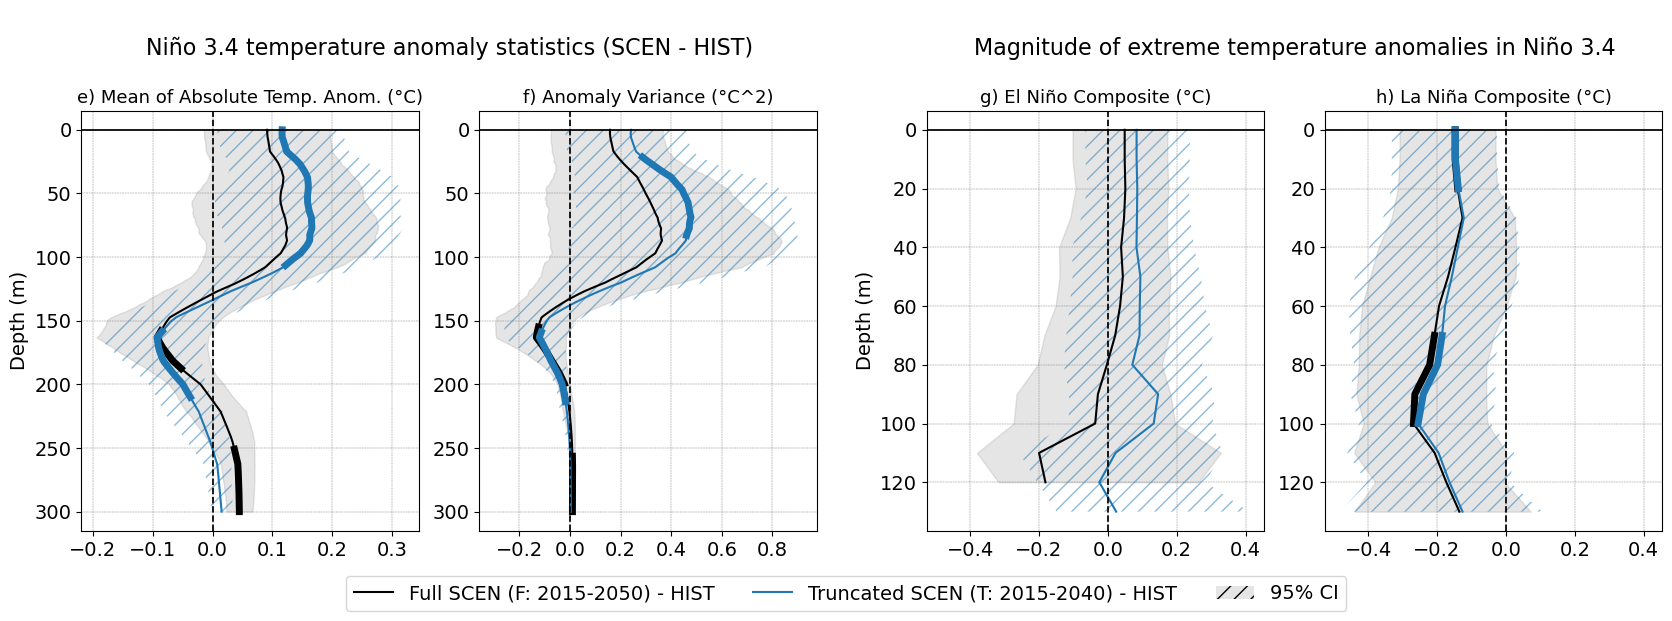

In [14]:
# =============================================================================
# FIGURE B2 (PART 2): NIÑO 3.4 ANOMALY STATISTICS AND EXTREME ANOMALY PROFILES (PANELS e-h)
# =============================================================================
# Two pairs of panels side by side: e-f (mean / variance differences) and g-h (El Niño / La Niña intensity differences)
fig = plt.figure(figsize=(17, 6))
outer = fig.add_gridspec(1, 2, wspace=0.15,
                         left=0.05, right=0.98, bottom=0.15, top=0.85)
gs_L = outer[0, 0].subgridspec(1, 2, wspace=0.18)   # e, f
gs_R = outer[0, 1].subgridspec(1, 2, wspace=0.18)   # g, h

axes = [fig.add_subplot(gs_L[0, 0]), fig.add_subplot(gs_L[0, 1]),
        fig.add_subplot(gs_R[0, 0]), fig.add_subplot(gs_R[0, 1])]
axes[1].sharey(axes[0]) # e and f share depth
axes[3].sharey(axes[2]) # g and h share depth and x-axis
axes[3].sharex(axes[2])

# Helper function to plot a depth profile, bold where significant, with an optional 95% interval (hatched or grey)
def plot_profile(ax, depth, x, sig, color, label, lo=None, hi=None, hatched=False):
    """
    Plot a depth profile, bold where significant, with an optional 95% interval.

    Parameters
    ----------
    ax (matplotlib.axes.Axes) : Axis to plot on.
    depth (xr.DataArray)      : Depths (y-axis).
    x (xr.DataArray)          : Profile values (x-axis).
    sig (xr.DataArray)        : Boolean mask; the profile is drawn thicker where True.
    color (any)               : Line colour.
    label (str or None)       : Legend label.
    lo (xr.DataArray)         : Lower bound of the 95% interval. Default is None (no interval).
    hi (xr.DataArray)         : Upper bound of the 95% interval. Default is None (no interval).
    hatched (bool)            : If True, the interval is hatched in 'color'; otherwise it is filled grey.
                                Default is False.
    """
    ax.plot(x, depth, color=color, label=label)
    ax.plot(x.where(sig), depth, color=color, lw=5)
    if lo is None or hi is None:
        return
    if hatched:
        ax.fill_betweenx(depth, lo, hi, facecolor="none", edgecolor=color,
                         hatch="//", lw=0, alpha=.5)
    else:
        ax.fill_betweenx(depth, lo, hi, color="gray", alpha=.2)

# Panels e-f: SCEN - HIST differences in the mean absolute anomaly and the anomaly variance (bold where p < 0.05)
for ax, var in zip(axes[:2], ["mean", "var"]):
    for group, c, label in [("SCEN_F-HIST", "k", "Full SCEN (F: 2015-2050) - HIST"), ("SCEN_T-HIST", "C0", "Truncated SCEN (T: 2015-2040) - HIST")]:
        d = SCEN_HIST_DIFF.sel(group=group)
        boot = d[f"{var}_boot"]
        plot_profile(ax, d.depth, d[var], d[f"pval_{var}"] < 0.05, c, label,
                     lo=boot.quantile(0.025, dim="boot"),
                     hi=boot.quantile(0.975, dim="boot"),
                     hatched=(group == "SCEN_T-HIST"))

# Panels g-h: SCEN - HIST differences in the intensity of El Niño / La Niña extremes (bold where significant)
for ax, phase in zip(axes[2:], ["EL-NINO", "LA-NINA"]):
    for key, c in [("F", "k"), ("T", "C0")]:
        ds = BOOTSTRAP_DIR_BIAS[key][phase].sel(type="INTENSITY")
        plot_profile(ax, ds.depth, ds["D"], ds["sig"], c, None,
                     lo=ds.get("lo"), hi=ds.get("hi"), hatched=(key == "T"))

# Axes styling and labels; one inversion per pair of shared axes (inverting axes[0] alone would not affect axes[2:])
axes[0].invert_yaxis()
axes[2].invert_yaxis()

axes[0].set_title("e) Mean of Absolute Temp. Anom. (°C)", fontsize=13)
axes[1].set_title("f) Anomaly Variance (°C^2)", fontsize=13)
axes[2].set_title("g) El Niño Composite (°C)", fontsize=13)
axes[3].set_title("h) La Niña Composite (°C)", fontsize=13)

for ax in axes:
    ax.axvline(0, color="k", ls="--", lw=1.25)
    ax.axhline(0, color="k", lw=1.25)
    ax.grid(True, color="gray", ls="--", lw=0.35)
    ax.tick_params(axis="both", labelsize = 14)
axes[0].set_ylabel("Depth (m)", fontsize=14)
axes[2].set_ylabel("Depth (m)", fontsize=14)
axes[0].set_xticks([-0.2, -0.1, 0, 0.1, 0.2, 0.3])
axes[1].set_xticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8])

# Common legend: line handles of all panels (deduplicated) + a patch for the 95% interval
legend = {l: h for ax in axes for h, l in zip(*ax.get_legend_handles_labels())}
legend["95% CI"] = Patch(facecolor=to_rgba("gray", 0.2), edgecolor="k",
                         hatch="//", linewidth=0)

fig.legend(legend.values(), legend.keys(), loc="lower center",
           ncol=5, frameon=True, bbox_to_anchor=(0.5, 0), fontsize = 14)

# Title above each pair of panels, centred on the pair
pair_titles = [
    (axes[:2], "Niño 3.4 temperature anomaly statistics (SCEN - HIST)"),
    (axes[2:], "Magnitude of extreme temperature anomalies in Niño 3.4"),
]
for pair, title in pair_titles:
    x0, x1 = pair[0].get_position().x0, pair[1].get_position().x1
    fig.text((x0 + x1) / 2, 0.935, "\n" + title, ha="center", va="bottom", fontsize=16)

fig.savefig(f"{FIG_DIR}figure_B2_pt2.png", dpi = 300, bbox_inches = 'tight')


In [15]:
# =============================================================================
# MERGING BOTH FIGURES ABOVE INTO A SINGLE FIGURE
# =============================================================================
merge_pngs_vertical(
    [
        f"{FIG_DIR}figure_B2_pt1.png",
        f"{FIG_DIR}figure_B2_pt2.png",
    ],
    f"{FIG_DIR}figure_B2.png",
)

### Table B1: Summary of SCEN-HIST changes in ENSO characteristics in HighResMIP models for the full (F; 2015-2050) and truncated (T; 2015-2040) SCEN periods, relative to HIST (1979-2014).

In [16]:
# =============================================================================
# READING IN THE ONI STATISTICS (TABLE B1)
# =============================================================================
# ONI statistics of each experiment group, for the HighResMIP runs only, indexed by model name (the _HIST / _SCEN suffix is dropped)
oni_stats = {exp: pd.read_csv(f'{DATA_DIR}ONI_STATS_{label}.csv', index_col = 0).loc[EXP_DATASETS[exp]].rename(index = lambda name: name.split('_')[0])
             for exp, label in PERIOD_LABELS.items()}
# Variance ratio SCEN / HIST: squared ratio of the ONI standard deviations
for exp in ['SCEN_F', 'SCEN_T']:
    oni_stats[exp]['VAR_RATIO'] = (oni_stats[exp]['STD_ONI'] / oni_stats['HIST']['STD_ONI'])**2

In [21]:
# =============================================================================
# Z20 (THERMOCLINE DEPTH) DIFFERENCES DURING ENSO EVENTS, SCEN - HIST (TABLE B1)
# =============================================================================
# Z20 depths: HIST runs for 1979-2014 and SCEN runs for 2015-2050 (the files span longer periods)
Z20_DEPTHS = {}
for key, exps, (start, end) in [('HIST', HIGHRESMIP_EXPS_HIST, ('1979', '2014')), ('SCEN', HIGHRESMIP_EXPS_SCEN, ('2015', '2050'))]:
    z20_list = []
    for dataset in tqdm(exps):
        ds_z20 = xr.open_dataset(glob.glob(f'{Z20_DIR}Z20_DEPTHS_{dataset}_????-????.nc')[0])['z20']
        z20_list += [ds_z20.sel(time = slice(start, end)).assign_coords(dataset = [dataset])]
        del ds_z20
    # Concatenate along 'dataset' and load into memory
    Z20_DEPTHS[key] = xr.concat(z20_list, dim = 'dataset').compute()

# ENSO event timestamps of each experiment (written by enso_preprocessing.py): per dataset, lists of timestamps for 'EL-NINO' and 'LA-NINA'
ENSO_EVENT_TS = {}

for exp, label in PERIOD_LABELS.items():
    with open(f'{DATA_DIR}ENSO_EVENT_TIMESTAMPS_{label}.pkl', 'rb') as f:
        ENSO_EVENT_TS[exp] = pickle.load(f)

# Helper function to compute the Z20 anomaly (m) of El Niño and La Niña events for each dataset
def z20_composite(da_z20, enso_timestamps):
    """
    Compute the Z20 anomaly of El Niño and La Niña events for each dataset.

    For each dataset, the mean Z20 over the event months minus the period-mean Z20, both averaged over the
    longitudes in 'lon_range' (210-270E, the Niño 3 band).

    Parameters
    ----------
    da_z20 (xr.DataArray)  : Z20 depths with dims (dataset, time, lon).
    enso_timestamps (dict) : Event timestamps keyed by dataset name and by phase, for example:
                             {'HadGEM3-GC31-HH_HIST': {'EL-NINO': [[ts1, ts2, ...], ...],
                                                       'LA-NINA': [[ts1, ts2, ...], ...]}, ...}

    Returns
    -------
    xr.DataArray : Z20 anomaly (m) with dims 'event' ('EL-NINO', 'LA-NINA') and 'dataset' (model names, without the
                   _HIST / _SCEN suffix).
    """
    en, ln = [], []
    lon_range = (210,270) # 210-270°E (150°W-90°W), the longitude band of Niño 3
    for dataset in da_z20.dataset.values:
        z = da_z20.sel(dataset = dataset, lon = slice(*lon_range))
        baseline = z.mean(dim = ['time', 'lon'])
        en += [z.sel(time = flatten(enso_timestamps[dataset]['EL-NINO'])).mean(dim = ['time', 'lon']) - baseline]
        ln += [z.sel(time = flatten(enso_timestamps[dataset]['LA-NINA'])).mean(dim = ['time', 'lon']) - baseline]

    en, ln = xr.concat(en, dim = 'dataset'), xr.concat(ln, dim = 'dataset')
    n3_enso_z20 = xr.concat((en.expand_dims({'event':['EL-NINO']}), ln.expand_dims({'event':['LA-NINA']})), dim='event')
    # Keep the model name only (drop the _HIST / _SCEN suffix)
    n3_enso_z20 = n3_enso_z20.assign_coords(
        dataset=[str(name).rsplit("_", 1)[0] for name in n3_enso_z20.dataset.values]
    )
    return n3_enso_z20

# Z20 anomalies during ENSO events for each experiment (SCEN_T: first part of the SCEN runs, 2015-2040)
n3_enso_z20 = {}
n3_enso_z20['HIST'] = z20_composite(da_z20 = Z20_DEPTHS['HIST'], enso_timestamps = ENSO_EVENT_TS['HIST'])
n3_enso_z20['SCEN_F'] = z20_composite(da_z20 = Z20_DEPTHS['SCEN'], enso_timestamps = ENSO_EVENT_TS['SCEN_F'])
n3_enso_z20['SCEN_T'] = z20_composite(da_z20 = Z20_DEPTHS['SCEN'].sel(time = slice('2015', '2040')),
                                       enso_timestamps = ENSO_EVENT_TS['SCEN_T'])

# SCEN_F - HIST and SCEN_T - HIST differences (m): one row per model, one column per event type
diff_z20 = {}
for exp in ['SCEN_F', 'SCEN_T']:
    diff = n3_enso_z20[exp] - n3_enso_z20['HIST']
    diff_z20[exp] = pd.DataFrame({'EN-Z20-DIFF': diff.sel(event = 'EL-NINO').values,
                                  'LN-Z20-DIFF': diff.sel(event = 'LA-NINA').values},
                                 index = n3_enso_z20['HIST'].dataset.values)

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

In [22]:
# =============================================================================
# ENSO FLAVOUR PROPORTIONS, SCEN - HIST (TABLE B1)
# =============================================================================
# Proportions of EP / CP El Niño (EP-EN, CP-EN) and La Niña (EP-LN, CP-LN) events of each experiment group, in %, for the
# HighResMIP runs only, indexed by model name
enso_flavour_prop = {exp: pd.read_csv(f'{DATA_DIR}ENSO_FLAVOUR_PROPORTIONS_{label}.csv', index_col = 0).loc[EXP_DATASETS[exp]]
                                                                                      .rename(index = lambda name: name.split('_')[0])[['EP-EN', 'CP-EN', 'EP-LN', 'CP-LN']]*100
                     for exp, label in PERIOD_LABELS.items()}

# SCEN_F - HIST and SCEN_T - HIST differences (percentage points)
diff_enso_flav = {exp: enso_flavour_prop[exp] - enso_flavour_prop['HIST'] for exp in ['SCEN_F', 'SCEN_T']}

In [23]:
# =============================================================================
# TABLE B1: SCEN - HIST DIFFERENCES OF ALL STATISTICS, PER PERIOD (F, T)
# =============================================================================
# ONI differences: mean event duration (months) and mean peak intensity (°C)
ONI_DIFF_COLS = ['EN_MEAN_DUR', 'LN_MEAN_DUR', 'EN_MEAN_MAX_INTENSITY', 'LN_MEAN_MAX_INTENSITY']

# One table per SCEN period (F, T), one row per model: ONI differences, the variance ratio SCEN / HIST (a ratio, not a difference),
# Z20 differences (m) and flavour-proportion differences (percentage points)
diffs = {period: pd.concat([(oni_stats[exp] - oni_stats['HIST'])[ONI_DIFF_COLS], oni_stats[exp][['VAR_RATIO']], diff_z20[exp], diff_enso_flav[exp]], axis = 1)
         for period, exp in [('F', 'SCEN_F'), ('T', 'SCEN_T')]}

In [32]:
# =============================================================================
# TABLE B1: MERGING THE F AND T TABLES, FORMATTING AND COUNTING
# =============================================================================
# Stack the F and T tables with a (dataset, period) MultiIndex, ordered as in HIGHRESMIP_MODELS with F followed by T for each
# model; period F = full SCEN (2015-2050), T = truncated SCEN (2015-2040)
ordered_index = pd.MultiIndex.from_product([HIGHRESMIP_MODELS, ["F", "T"]], names=["dataset", "period"])
merged_diff = pd.concat(diffs, names=["period", "dataset"]).swaplevel().reindex(ordered_index)

# Decimal places shown for each column
decimals = {'EN_MEAN_DUR': 1, 'LN_MEAN_DUR': 1,
            'EN_MEAN_MAX_INTENSITY': 2, 'LN_MEAN_MAX_INTENSITY': 2,
            'VAR_RATIO': 2,
            'EN-Z20-DIFF': 1, 'LN-Z20-DIFF': 1,
            'EP-EN': 1, 'CP-EN': 1, 'EP-LN': 1, 'CP-LN': 1}
merged_diff_rounded = merged_diff.round(decimals)
# Columns shown without a sign: the variance ratio is a ratio, not a difference
unsigned = {'VAR_RATIO'}

# Helper function to format a value with nd decimals, signed for differences and with no sign on zero
def fmt(x, nd, signed):
    """
    Format a value to nd decimals, signed or not, with no sign on zero.
    """
    s = f"{x:+.{nd}f}" if signed else f"{x:.{nd}f}"
    return s.replace('+0.0', '0.0').replace('-0.0', '0.0') if float(s) == 0 else s  # no +0.0 / -0.0
# Formatted (string) version of the table, as saved in the CSV and shown below
merged_diff_signed = merged_diff.copy().astype(object)
for col, nd in decimals.items():
    merged_diff_signed[col] = merged_diff[col].apply(fmt, nd=nd, signed=col not in unsigned)

# Number of models (out of 6) with an increase in each statistic, per period: rounded value > 0 (variance ratio > 1)
thresholds = pd.Series({col: 1.0 if col == 'VAR_RATIO' else 0.0 for col in merged_diff_rounded.columns})
counts = merged_diff_rounded.gt(thresholds, axis = 1).groupby(level='period').sum()

In [34]:
# =============================================================================
# TABLE B1: SAVING AND DISPLAYING THE TABLE
# =============================================================================
merged_diff_signed.to_csv(f"{DATA_DIR}ENSO_STATS_DIFF_SCEN_F-T-HIST_2015-2050.csv", index=True)
merged_diff_signed

EN_MEAN_DUR LN_MEAN_DUR EN_MEAN_MAX_INTENSITY  \
dataset         period                                                 
HadGEM3-GC31-HH F             +3.7        +1.7                 +0.26   
                T             +1.1        +2.4                 +0.23   
EC-Earth3P-HR   F             +2.1        -0.2                 +0.27   
                T             +2.4         0.0                 +0.29   
CNRM-CM6-1-HR   F             +3.5        +1.4                 +0.18   
                T             +1.3        +1.4                 +0.24   
CMCC-CM2-VHR4   F             +8.1        +0.7                 +0.17   
                T             +7.9        +0.4                 +0.20   
MPI-ESM1-2-HR   F             +3.4        +6.1                 +0.16   
                T             +3.5        +6.1                 +0.19   
MPI-ESM1-2-XR   F             -1.3        +2.5                 -0.29   
                T             -0.7        +2.5                 -0.28   

                       LN_MEAN_MAX_INTENSITY VAR_RATIO EN-Z20-DIFF  \
dataset         period                                               
HadGEM3-GC31-HH F                      +0.31      1.84        -1.9   
                T                      +0.40      1.96        -0.6   
EC-Earth3P-HR   F                      +0.24      1.20        -2.1   
                T                      +0.10      1.22        -1.1   
CNRM-CM6-1-HR   F                      +0.09      1.73        -4.2   
                T                      +0.09      1.82        -3.5   
CMCC-CM2-VHR4   F                      +0.26      1.00        -1.6   
                T                      +0.27      1.10        -0.8   
MPI-ESM1-2-HR   F                      +0.17      1.17        +1.2   
                T                      +0.17      1.44        +1.7   
MPI-ESM1-2-XR   F                      +0.15      0.76        -2.7   
                T                      +0.15      0.88        -2.6   

                       LN-Z20-DIFF  EP-EN  CP-EN  EP-LN  CP-LN  
dataset         period                                          
HadGEM3-GC31-HH F             -5.1  +19.2  -17.2   -4.8   +4.8  
                T             -4.8  +12.7   -1.6    0.0    0.0  
EC-Earth3P-HR   F             -1.4  +10.0   +3.3  -35.0  +27.5  
                T             -0.9  +35.0   -5.0  -17.1   +4.3  
CNRM-CM6-1-HR   F             -2.3  +54.5  -40.3  -19.0  +19.0  
                T             -1.6  +57.1  -42.9  -19.0  +19.0  
CMCC-CM2-VHR4   F             -0.7  +35.2  -42.0  +20.6  -20.6  
                T             -0.8  +52.7  -54.5  +11.1  -11.1  
MPI-ESM1-2-HR   F             -1.2  +26.4  -25.0  +17.5  -17.5  
                T             -1.3  +23.2  -25.0   -2.5  -17.5  
MPI-ESM1-2-XR   F             -3.1  +63.3  -73.3    0.0    0.0  
                T             -2.8  +54.8  -83.3    0.0    0.0

In [35]:
# Number of models (out of 6) with an increase in each statistic, per period (displayed only, not saved)
counts

,EN_MEAN_DUR,LN_MEAN_DUR,EN_MEAN_MAX_INTENSITY,LN_MEAN_MAX_INTENSITY,VAR_RATIO,EN-Z20-DIFF,LN-Z20-DIFF,EP-EN,CP-EN,EP-LN,CP-LN
period,,,,,,,,,,,
F,5,5,5,6,4,1,0,6,1,2,3
T,5,5,5,6,5,1,0,6,0,1,2
